# Proyek Analisis Data: [Air Quality Dataset]
- **Nama:** [Syifaunnisa']
- **Email:** [Syifauniisaa@gmail.com]
- **ID Dicoding:** [DS322B6X1701]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana perubahan rata-rata konsentrasi PM2.5 setiap bulan di stasiun Aotizhongxin selama periode Maret 2013–Februari 2017, dan pada bulan apa rata-rata konsentrasi PM2.5 mencapai nilai tertinggi?
- **Pertanyaan 2:** Bagaimana perbandingan rata-rata konsentrasi PM2.5, PM10, SO2, NO2, CO, dan O3 di seluruh stasiun pemantauan selama periode Maret 2013–Februari 2017, serta stasiun mana yang memiliki rata-rata konsentrasi PM2.5 tertinggi?
- **Pertanyaan 3:** Bagaimana hubungan antara suhu (TEMP), titik embun (DEWP), kecepatan angin (WSPM), dan konsentrasi PM2.5 selama periode Maret 2013–Februari 2017 pada stasiun pemantauan kualitas udara?

## Import Semua Packages/Library yang Digunakan

In [310]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob

## Data Wrangling

### Gathering Data

#### Load df ...

In [315]:
folder_path = "D:/DICODING/SUMBISSION DA/Air-quality-dataset/PRSA_Data_20130301-20170228"

files = glob.glob(os.path.join(folder_path, "PRSA_Data_*.csv"))
data = []

for file in files:
    df_temp = pd.read_csv(file)
    station = os.path.basename(file).replace("PRSA_Data_", "")
    station = station.split("_20130301")[0]
    df_temp["station"] = station
    data.append(df_temp)

df = pd.concat(data, ignore_index=True)
print("Ukuran data:", df.shape)
print("Jumlah stasiun:", df["station"].nunique())
print(df["station"].unique())
df.head()

Ukuran data: (420768, 18)
Jumlah stasiun: 12
['Aotizhongxin' 'Changping' 'Dingling' 'Dongsi' 'Guanyuan' 'Gucheng'
 'Huairou' 'Nongzhanguan' 'Shunyi' 'Tiantan' 'Wanliu' 'Wanshouxigong']


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


**Insight:** (Opsional)
- Pada data kualitas udara, terdapat beberapa kadar polutan dan juga tanggalnya, polutan tersebut meliputi PM2.5, PM10, SO2, NO2, CO, O3 dan juga suhu tekanan dan hujan atau tidak.
- data tersebut juga tersedia stasiun tempat dimana diambilnya ukuran kadar polutan tersebut sehingga kita bisa menganalisis stasiun mana yang memiliki polutan tertinggi

### Assessing Data

#### Identifying ... problem

In [320]:
df.shape

(420768, 18)

In [322]:
df["station"].value_counts()

station
Aotizhongxin     35064
Changping        35064
Dingling         35064
Dongsi           35064
Guanyuan         35064
Gucheng          35064
Huairou          35064
Nongzhanguan     35064
Shunyi           35064
Tiantan          35064
Wanliu           35064
Wanshouxigong    35064
Name: count, dtype: int64

In [324]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  object 
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 57.8+ MB


In [326]:
df.describe(include = "all")

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
count,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,412029.000000,414319.000000,411747.000000,408652.000000,400067.000000,407491.000000,420370.000000,420375.000000,420365.000000,420378.000000,418946,420450.000000,420768
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16,NaN,12
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NE,NaN,Aotizhongxin
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,43335,NaN,35064
mean,17532.500000,2014.662560,6.522930,15.729637,11.500000,79.793428,104.602618,15.830835,50.638586,1230.766454,57.372271,13.538976,1010.746982,2.490822,0.064476,NaN,1.729711,NaN
std,10122.116943,1.177198,3.448707,8.800102,6.922195,80.822391,91.772426,21.650603,35.127912,1160.182716,56.661607,11.436139,10.474055,13.793847,0.821004,NaN,1.246386,NaN
min,1.000000,2013.000000,1.000000,1.000000,0.000000,2.000000,2.000000,0.285600,1.026500,100.000000,0.214200,-19.900000,982.400000,-43.400000,0.000000,NaN,0.000000,NaN
25%,8766.750000,2014.000000,4.000000,8.000000,5.750000,20.000000,36.000000,3.000000,23.000000,500.000000,11.000000,3.100000,1002.300000,-8.900000,0.000000,NaN,0.900000,NaN
50%,17532.500000,2015.000000,7.000000,16.000000,11.500000,55.000000,82.000000,7.000000,43.000000,900.000000,45.000000,14.500000,1010.400000,3.100000,0.000000,NaN,1.400000,NaN
75%,26298.250000,2016.000000,10.000000,23.000000,17.250000,111.000000,145.000000,20.000000,71.000000,1500.000000,82.000000,23.300000,1019.000000,15.100000,0.000000,NaN,2.200000,NaN


In [327]:
df.isnull().sum()

No             0
year           0
month          0
day            0
hour           0
PM2.5       8739
PM10        6449
SO2         9021
NO2        12116
CO         20701
O3         13277
TEMP         398
PRES         393
DEWP         403
RAIN         390
wd          1822
WSPM         318
station        0
dtype: int64

In [330]:
df.duplicated().sum()

0

**Steps to Take:**
- memeriksa jumlah data perstasiun
- melihat apakah tipe data pada tanggal sudah sesuai
- melihat summary statistik untuk mengetahui apakah ada outlier
- melihat apakah ada null (missing value)
- melihat apakah ada data duplikat (sama persis)

**Insight:** (Opsional)
- Ukuran Data: Data ini memiliki 420768 baris, dan 18 kolom
- Data Stasiun: Data per Stasiun sudah seimbang antar stasiun.
- Missing Values: Ditemukan nilai kosong pada beberapa variabel, terutama variabel polutan seperti PM2.5, PM10, SO2, NO2, CO, dan O3. Oleh karena itu, diperlukan penanganan missing values sebelum data digunakan untuk analisis lebih lanjut.
- Tipe Data Waktu: Kolom year, month, day, dan hour masih disimpan secara terpisah dengan tipe data integer. Untuk mempermudah analisis tren kualitas udara berdasarkan waktu, kolom-kolom tersebut dapat digabungkan menjadi satu kolom bertipe datetime.
- Indikasi Nilai Ekstrem: Berdasarkan statistik deskriptif, terdapat nilai maksimum yang cukup tinggi pada beberapa variabel. Kondisi ini perlu diperiksa lebih lanjut menggunakan boxplot atau metode IQR untuk mengetahui apakah nilai tersebut termasuk outlier.
- Data Duplikat: Berdasarkan pemeriksaan menggunakan df.duplicated().sum(), tidak ditemukan baris duplikat dalam dataset.

### Cleaning Data

#### Fixing ... problem

In [336]:
df["datetime"] = pd.to_datetime({
    "year": df["year"],
    "month": df["month"],
    "day": df["day"],
    "hour": df["hour"]
})

df.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01 03:00:00
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01 04:00:00


In [338]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 19 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   No        420768 non-null  int64         
 1   year      420768 non-null  int64         
 2   month     420768 non-null  int64         
 3   day       420768 non-null  int64         
 4   hour      420768 non-null  int64         
 5   PM2.5     412029 non-null  float64       
 6   PM10      414319 non-null  float64       
 7   SO2       411747 non-null  float64       
 8   NO2       408652 non-null  float64       
 9   CO        400067 non-null  float64       
 10  O3        407491 non-null  float64       
 11  TEMP      420370 non-null  float64       
 12  PRES      420375 non-null  float64       
 13  DEWP      420365 non-null  float64       
 14  RAIN      420378 non-null  float64       
 15  wd        418946 non-null  object        
 16  WSPM      420450 non-null  float64    

In [340]:
kolom_numerik = [
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM"
]

for kolom in kolom_numerik:
    df[kolom] = df[kolom].fillna(
        df.groupby("station")[kolom].transform("median")
    )

In [342]:
df.isna().sum()

No             0
year           0
month          0
day            0
hour           0
PM2.5          0
PM10           0
SO2            0
NO2            0
CO             0
O3             0
TEMP           0
PRES           0
DEWP           0
RAIN           0
wd          1822
WSPM           0
station        0
datetime       0
dtype: int64

In [344]:
df['wd'].value_counts()

wd
NE     43335
ENE    34142
NW     32600
N      30869
E      29752
SW     28756
NNE    28232
NNW    25326
WNW    24375
ESE    24220
SSW    22563
SE     20074
WSW    20040
S      19405
SSE    17694
W      17563
Name: count, dtype: int64

In [346]:
df["wd"] = df["wd"].fillna(
    df.groupby("station")["wd"].transform(
        lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan
    )
)

In [348]:
df.isna().sum()

No          0
year        0
month       0
day         0
hour        0
PM2.5       0
PM10        0
SO2         0
NO2         0
CO          0
O3          0
TEMP        0
PRES        0
DEWP        0
RAIN        0
wd          0
WSPM        0
station     0
datetime    0
dtype: int64

In [384]:
df.to_csv("main_data.csv", index=False)

**Insight:** (Opsional)
- Menggabungkan kolom year, month, day, dan hour menjadi kolom baru bernama datetime untuk mempermudah analisis tren kualitas udara berdasarkan waktu.
- Menangani missing value pada variabel numerik menggunakan median karena relatif tahan terhadap pengaruh nilai ekstrem (outlier), sedangkan variabel kategorik ditangani menggunakan modus.
- Mempertahankan outlier yang ditemukan selama tidak terdapat bukti bahwa nilai tersebut merupakan kesalahan pencatatan, karena nilai ekstrem PM2.5 dapat mencerminkan kondisi polusi udara yang tinggi.

## Exploratory Data Analysis (EDA)

### Explore ...

In [353]:
bulan_tertinggi = tren_pm25.idxmax()
nilai_tertinggi = tren_pm25.max()

print("Bulan dengan rata-rata PM2.5 tertinggi:", bulan_tertinggi.strftime("%B %Y"))
print("Rata-rata PM2.5 tertinggi:", round(nilai_tertinggi, 2))

Bulan dengan rata-rata PM2.5 tertinggi: December 2015
Rata-rata PM2.5 tertinggi: 153.0


In [355]:
df.groupby(by="station").agg({
    "PM2.5": ["max", "min", "mean", "std","median"]
})

PM2.5                                  
                 max  min       mean        std median
station                                               
Aotizhongxin   898.0  3.0  82.120075  81.142233   58.0
Changping      882.0  2.0  70.545694  71.619188   46.0
Dingling       881.0  3.0  65.434317  71.555278   41.0
Dongsi         737.0  3.0  85.655404  85.721734   61.0
Guanyuan       680.0  2.0  82.512914  80.281010   59.0
Gucheng        770.0  2.0  83.412651  82.092868   60.0
Huairou        762.0  2.0  69.011408  70.346593   47.0
Nongzhanguan   844.0  2.0  84.375713  85.518369   59.0
Shunyi         941.0  2.0  78.853887  80.261997   55.0
Tiantan        821.0  3.0  81.717653  80.199730   59.0
Wanliu         957.0  2.0  83.109169  81.497468   59.0
Wanshouxigong  999.0  3.0  84.527421  85.189931   60.0

In [357]:
df[df["station"] == "Aotizhongxin"].groupby(["year"]).agg({
    "PM2.5": ["mean", "median", "max", "min"]
}).round(2)

PM2.5                   
       mean median    max  min
year                          
2013  82.36   62.0  665.0  3.0
2014  88.91   64.0  584.0  3.0
2015  81.52   57.0  657.0  3.0
2016  73.78   51.0  898.0  3.0
2017  94.35   48.0  713.0  3.0

In [359]:
df.groupby(by="station").agg({
    "PM2.5": "mean",
    "PM10": ["mean", "median"],
    "SO2": ["mean", "median"],
    "NO2": ["mean", "median"],
    "CO": ["mean", "median"],
    "O3": ["mean", "median"]
}).round(2)

PM2.5    PM10           SO2           NO2              CO  \
                mean    mean median   mean median   mean median     mean   
station                                                                    
Aotizhongxin   82.12  109.59   87.0  17.15    9.0  59.12   53.0  1244.56   
Changping      70.55   94.28   72.0  14.82    7.0  44.03   36.0  1137.02   
Dingling       65.43   83.30   60.0  11.61    5.0  27.28   19.0   887.40   
Dongsi         85.66  109.95   86.0  18.37   10.0  53.39   47.0  1299.97   
Guanyuan       82.51  108.78   89.0  17.46    8.0  57.77   51.0  1252.73   
Gucheng        83.41  118.65   99.0  15.25    7.0  55.76   50.0  1307.03   
Huairou        69.01   90.98   69.0  11.89    4.0  32.15   25.0  1013.53   
Nongzhanguan   84.38  108.69   85.0  18.57    9.0  57.96   51.0  1309.75   
Shunyi         78.85   98.40   77.0  13.26    5.0  43.64   37.0  1163.02   
Tiantan        81.72  106.00   85.0  14.13    7.0  53.03   47.0  1285.51   
Wanliu         83.11  110.28   88.0  18.24   10.0  65.10   60.0  1297.68   
Wanshouxigong  84.53  111.93   91.0  16.97    8.0  55.39   49.0  1356.69   

                          O3         
               median   mean median  
station                              
Aotizhongxin    900.0  55.65  42.00  
Changping       800.0  57.73  46.00  
Dingling        600.0  68.29  61.00  
Dongsi         1000.0  56.96  44.13  
Guanyuan        900.0  55.30  41.00  
Gucheng         900.0  57.43  45.00  
Huairou         800.0  59.47  49.00  
Nongzhanguan    900.0  58.34  45.00  
Shunyi          800.0  54.68  43.00  
Tiantan         900.0  55.60  40.00  
Wanliu          900.0  47.86  32.00  
Wanshouxigong  1000.0  55.79  42.00

**Insight:** (Opsional)
- Terdapat perbedaan rata-rata konsentrasi polutan antarstasiun pemantauan. Dongsi memiliki rata-rata PM2.5 tertinggi sebesar 86,19, sedangkan Dingling memiliki rata-rata terendah sebesar 65,99.
- Stasiun Gucheng memiliki rata-rata PM10 tertinggi sebesar 118,86, sedangkan Dingling memiliki rata-rata terendah sebesar 83,74.
- Untuk SO2, rata-rata tertinggi terdapat di Nongzhanguan sebesar 18,69, sedangkan rata-rata terendah terdapat di Dingling sebesar 11,75.
- Untuk NO2, rata-rata tertinggi terdapat di Wanliu sebesar 65,26, sedangkan rata-rata terendah terdapat di Dingling sebesar 27,59.
- Untuk CO, rata-rata tertinggi terdapat di Wanshouxigong sebesar 1.370,40, sedangkan rata-rata terendah terdapat di Dingling sebesar 904,90.
- Berbeda dari polutan lainnya, O3 memiliki rata-rata tertinggi di Dingling sebesar 68,55 dan terendah di Wanliu sebesar 48,87.
- Secara keseluruhan, Dingling memiliki rata-rata terendah untuk lima dari enam polutan yang dianalisis, yaitu PM2.5, PM10, SO2, NO2, dan CO. Sementara itu, Wanshouxigong memiliki rata-rata CO tertinggi.
- Perbedaan nilai mean dan median pada beberapa polutan menunjukkan bahwa distribusi konsentrasi berpotensi menceng ke kanan. Hal ini dapat mengindikasikan adanya sejumlah pengamatan dengan konsentrasi tinggi.
- Hasil analisis ini menunjukkan adanya variasi konsentrasi polutan antarstasiun. Analisis tren berdasarkan waktu dan korelasi antarpolutan dapat dilakukan lebih lanjut untuk memahami pola perubahan kualitas udara dan hubungan antara jenis polutan.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

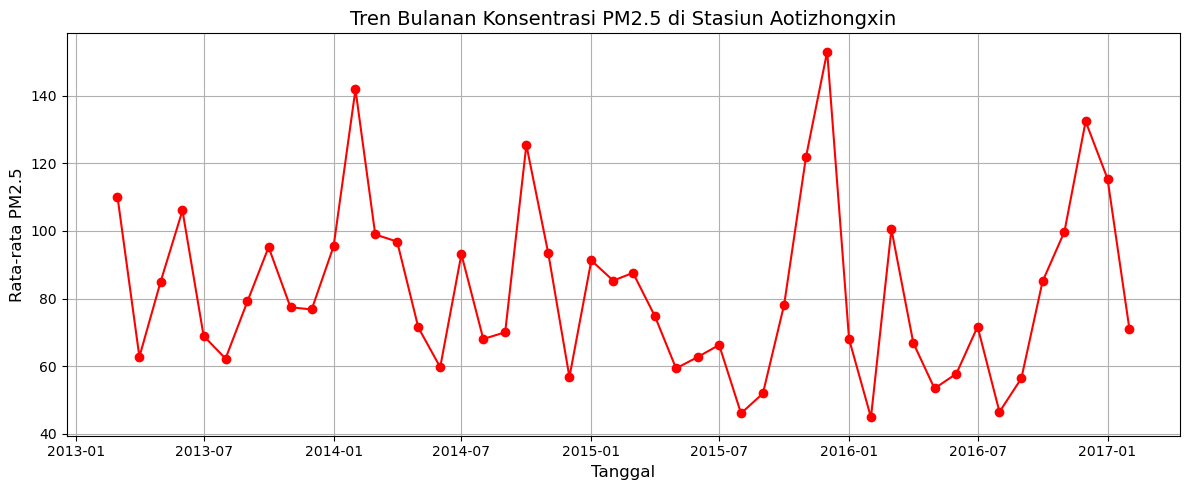

In [364]:
df_aotizhongxin = df[df["station"] == "Aotizhongxin"].copy()

df_aotizhongxin["datetime"] = pd.to_datetime({
    "year": df_aotizhongxin["year"],
    "month": df_aotizhongxin["month"],
    "day": df_aotizhongxin["day"],
    "hour": df_aotizhongxin["hour"]
})

tren_pm25 = (
    df_aotizhongxin
    .set_index("datetime")["PM2.5"]
    .resample("MS")
    .mean()
    .dropna()
)

plt.figure(figsize=(12, 5))
plt.plot(tren_pm25.index, tren_pm25.values, color="red", marker="o")

plt.xlabel("Tanggal", fontsize=12)
plt.ylabel("Rata-rata PM2.5", fontsize=12)
plt.title("Tren Bulanan Konsentrasi PM2.5 di Stasiun Aotizhongxin", fontsize=14)

plt.grid(True)
plt.tight_layout()
plt.show()

### Pertanyaan 2:

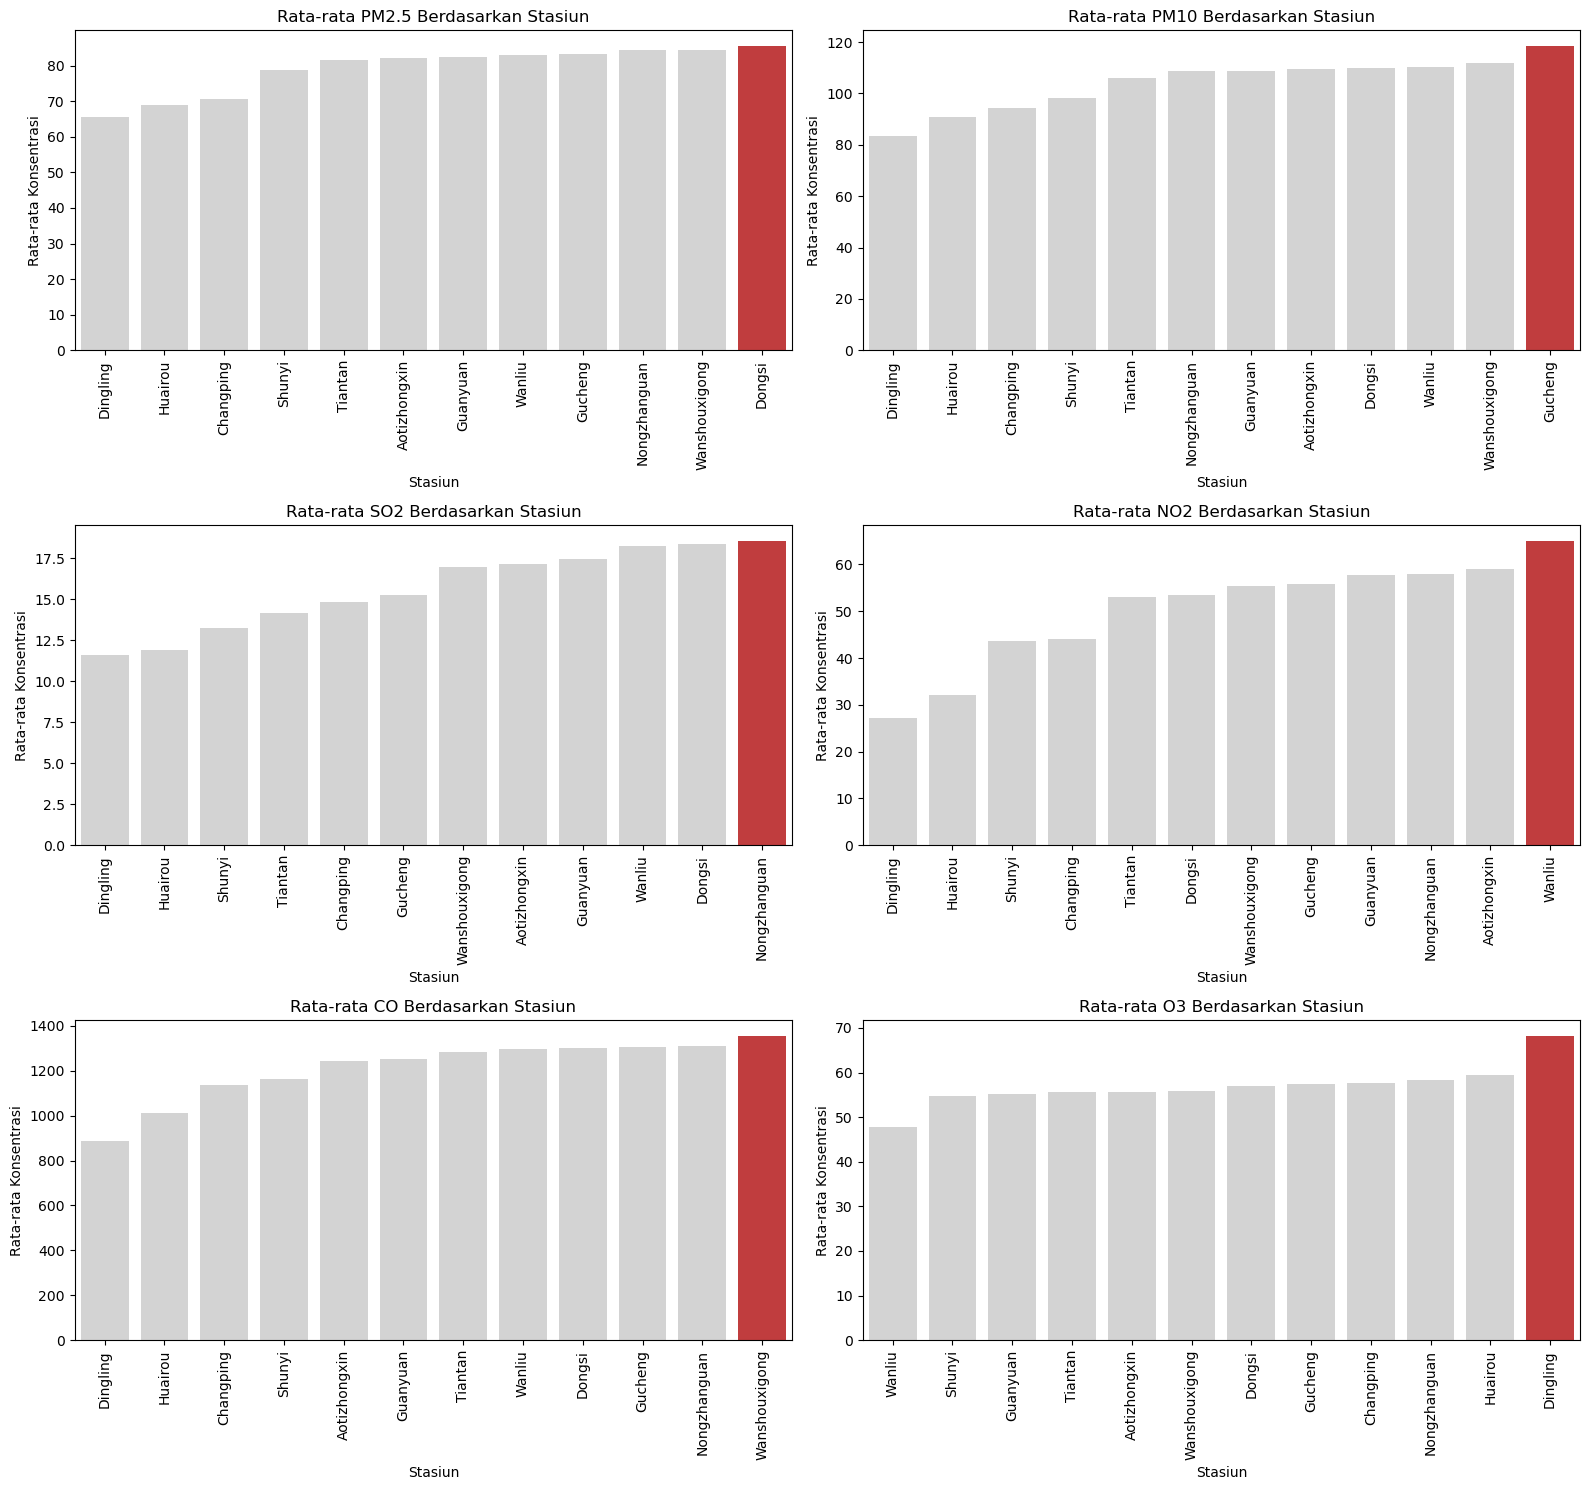

In [367]:
polutan = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]

fig, axes = plt.subplots(3, 2, figsize=(16, 15))

for i, kolom in enumerate(polutan):
    data_plot = df.groupby("station")[kolom].mean().reset_index()
    data_plot = data_plot.sort_values(by=kolom, ascending=True)

    sns.barplot(data=data_plot, x="station", y=kolom, ax=axes[i//2, i%2], hue="station", palette=colors, legend=False)
    axes[i//2, i%2].set_title("Rata-rata " + kolom + " Berdasarkan Stasiun")
    axes[i//2, i%2].set_xlabel("Stasiun")
    axes[i//2, i%2].set_ylabel("Rata-rata Konsentrasi")
    axes[i//2, i%2].tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

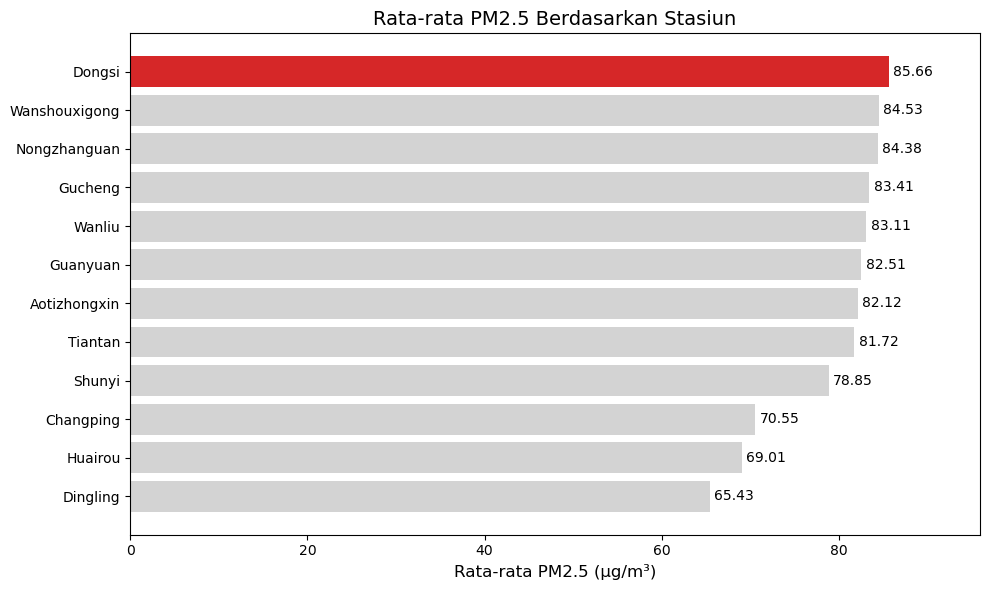

In [368]:
df1 = df.groupby("station")["PM2.5"].mean().reset_index()
df1 = df1.sort_values(by="PM2.5", ascending=True)

colors = ["#D3D3D3"] * (len(df1) - 1) + ["#D62728"]   # 11 abu-abu, 1 merah (tertinggi)

plt.figure(figsize=(10, 6))
plt.barh(y=df1["station"], width=df1["PM2.5"], color=colors)

for i, v in enumerate(df1["PM2.5"]):
    plt.text(v + 0.5, i, f"{v:.2f}", va="center", ha="left", fontsize=10)

plt.xlabel("Rata-rata PM2.5 (µg/m³)", fontsize=12)
plt.ylabel(None)
plt.title("Rata-rata PM2.5 Berdasarkan Stasiun", fontsize=14)
plt.xlim(0, df1["PM2.5"].max() * 1.12)   # ruang untuk label angka
plt.tight_layout()
plt.show()

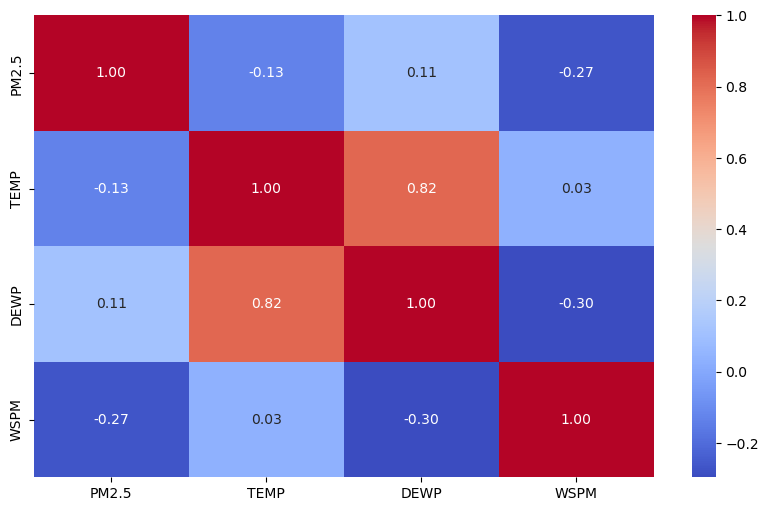

In [369]:
plt.figure(figsize=(10, 6))

sns.heatmap(df[["PM2.5", "TEMP", "DEWP", "WSPM"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")

plt.show()

**Insight:** (Opsional)
- Berdasarkan grafik tren bulanan, rata-rata konsentrasi PM2.5 di stasiun Aotizhongxin mengalami fluktuasi selama periode pengamatan. Konsentrasi PM2.5 meningkat dan menurun dari bulan ke bulan, sehingga belum menunjukkan tren penurunan yang konsisten.
- Terdapat beberapa bulan dengan peningkatan konsentrasi yang cukup tinggi, sementara pada bulan lainnya konsentrasi menurun secara signifikan. Hal ini menunjukkan bahwa tingkat pencemaran PM2.5 bervariasi sepanjang waktu.
- Berdasarkan diagram batang, Dongsi memiliki rata-rata konsentrasi PM2.5 tertinggi sebesar 86,19, sedangkan Dingling memiliki rata-rata terendah sebesar 65,99.
- Perbedaan tersebut menunjukkan bahwa konsentrasi PM2.5 tidak merata di seluruh stasiun pemantauan. Dongsi dapat menjadi salah satu prioritas pemantauan lebih lanjut karena memiliki rata-rata konsentrasi PM2.5 tertinggi di antara stasiun yang dianalisis.
- Dari ketiga variabel meteorologi yang dianalisis, kecepatan angin memiliki korelasi paling kuat dengan PM2.5, yaitu -0,27, meskipun hubungannya masih tergolong lemah. Sementara itu, suhu dan titik embun memiliki hubungan linear yang sangat lemah dengan PM2.5. Hasil ini menunjukkan bahwa perubahan PM2.5 kemungkinan juga dipengaruhi oleh faktor lain yang tidak dianalisis dalam heatmap ini.

## Analisis Lanjutan (Opsional)

In [372]:
df1 = df.groupby("station")["PM2.5"].mean().reset_index()

df1["Kategori"] = pd.cut(
    df1["PM2.5"],
    bins=[0, 50, 75, float("inf")],
    labels=["Rendah", "Sedang", "Tinggi"]
)

df1.sort_values(by="PM2.5", ascending=False, inplace=True)

df1

,station,PM2.5,Kategori
3,Dongsi,85.655404,Tinggi
11,Wanshouxigong,84.527421,Tinggi
7,Nongzhanguan,84.375713,Tinggi
5,Gucheng,83.412651,Tinggi
10,Wanliu,83.109169,Tinggi
4,Guanyuan,82.512914,Tinggi
0,Aotizhongxin,82.120075,Tinggi
9,Tiantan,81.717653,Tinggi
8,Shunyi,78.853887,Tinggi
1,Changping,70.545694,Sedang


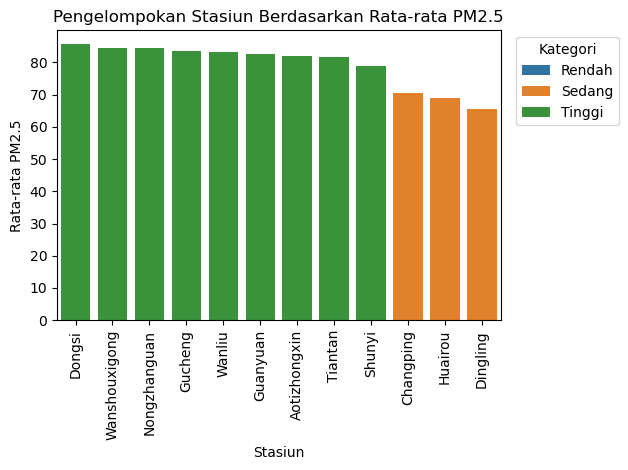

In [376]:
sns.barplot(data=df1, x="station", y="PM2.5", hue="Kategori")

plt.xticks(rotation=90)
plt.title("Pengelompokan Stasiun Berdasarkan Rata-rata PM2.5")
plt.xlabel("Stasiun")
plt.ylabel("Rata-rata PM2.5")
plt.legend(title="Kategori", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Analisis lanjutan menggunakan metode Manual Grouping bertujuan mengelompokkan stasiun pemantauan berdasarkan rata-rata konsentrasi PM2.5. Pengelompokan dilakukan menggunakan tiga kategori, yaitu rendah, sedang, dan tinggi, berdasarkan batas nilai yang ditentukan dalam analisis. Hasil pengelompokan digunakan untuk mengidentifikasi stasiun yang memiliki rata-rata konsentrasi PM2.5 relatif tinggi sehingga dapat menjadi prioritas pemantauan lebih lanjut. Kategori tersebut merupakan batas analisis yang ditentukan dalam proyek, bukan kategori resmi kualitas udara.
- Berdasarkan hasil manual grouping, stasiun pemantauan terbagi menjadi dua kategori, yaitu tinggi dan sedang. Tidak ada stasiun yang masuk kategori rendah berdasarkan batas pengelompokan yang telah ditentukan.
- Sebanyak 9 stasiun termasuk kategori tinggi karena memiliki rata-rata PM2.5 di atas 75, sedangkan 3 stasiun termasuk kategori sedang, yaitu Changping, Huairou, dan Dingling.
- Stasiun Dongsi memiliki rata-rata PM2.5 tertinggi, sekitar 86,19, sedangkan Dingling memiliki rata-rata terendah, sekitar 65,99.
- Hasil pengelompokan menunjukkan bahwa sebagian besar stasiun memiliki rata-rata konsentrasi PM2.5 di atas 75. Oleh karena itu, stasiun dalam kategori tinggi dapat diprioritaskan untuk pemantauan kualitas udara lebih lanjut.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Berdasarkan grafik tren bulanan, rata-rata konsentrasi PM2.5 di stasiun Aotizhongxin mengalami fluktuasi selama periode pengamatan Maret 2013–Februari 2017. Konsentrasi PM2.5 tidak menunjukkan tren penurunan yang konsisten dari bulan ke bulan. Rata-rata konsentrasi tertinggi terjadi pada Desember 2015 sebesar 153,0. Temuan ini menunjukkan bahwa terdapat periode tertentu ketika konsentrasi PM2.5 meningkat secara signifikan, sehingga pemantauan perlu dilakukan secara berkala untuk mengidentifikasi periode dengan tingkat pencemaran yang tinggi.
- **Conclusion pertanyaan 2:** Berdasarkan barplot perbandingan enam polutan, terdapat perbedaan rata-rata konsentrasi polutan antarstasiun pemantauan. Dongsi memiliki rata-rata PM2.5 tertinggi sebesar 86,19, sedangkan Dingling memiliki rata-rata PM2.5 terendah sebesar 65,99. Untuk polutan lainnya, Gucheng memiliki rata-rata PM10 tertinggi sebesar 118,86, Nongzhanguan memiliki rata-rata SO2 tertinggi sebesar 18,69, Wanliu memiliki rata-rata NO2 tertinggi sebesar 65,26, Wanshouxigong memiliki rata-rata CO tertinggi sebesar 1.370,40, dan Dingling memiliki rata-rata O3 tertinggi sebesar 68,55. Hasil ini menunjukkan bahwa stasiun dengan konsentrasi tertinggi berbeda-beda untuk setiap jenis polutan. Oleh karena itu, evaluasi kualitas udara perlu mempertimbangkan lokasi pemantauan dan karakteristik masing-masing polutan.
- **Conclusion pertanyaan 3:** Berdasarkan heatmap korelasi, PM2.5 memiliki korelasi negatif yang lemah dengan suhu sebesar -0,13 dan kecepatan angin sebesar -0,27, serta korelasi positif yang sangat lemah dengan titik embun sebesar 0,11. Di antara ketiga variabel meteorologi tersebut, kecepatan angin memiliki korelasi paling kuat dengan PM2.5. Namun, seluruh korelasi tersebut relatif lemah, sehingga suhu, titik embun, dan kecepatan angin belum cukup untuk menjelaskan variasi konsentrasi PM2.5 secara keseluruhan.

**Rekomendasi Action Item:**
- Meningkatkan pemantauan PM2.5 pada periode dengan konsentrasi tinggi. Pemantauan di stasiun Aotizhongxin perlu diperhatikan, terutama pada bulan-bulan ketika konsentrasi PM2.5 cenderung meningkat. Desember 2015 dapat dijadikan salah satu periode evaluasi karena memiliki rata-rata konsentrasi tertinggi sebesar 153,0. Analisis pola bulanan secara berkala dapat membantu mengidentifikasi periode yang berpotensi mengalami peningkatan pencemaran udara.
- Menentukan prioritas pemantauan berdasarkan lokasi dan jenis polutan. Stasiun Dongsi perlu mendapat perhatian dalam pemantauan PM2.5 karena memiliki rata-rata konsentrasi tertinggi. Sementara itu, pemantauan PM10 dapat difokuskan pada Gucheng, SO2 pada Nongzhanguan, NO2 pada Wanliu, CO pada Wanshouxigong, dan O3 pada Dingling. Pendekatan ini dapat membantu mengarahkan kegiatan pemantauan sesuai dengan karakteristik polutan di setiap stasiun.
- Mempertimbangkan faktor meteorologi dan faktor lain dalam analisis PM2.5. Karena korelasi TEMP, DEWP, dan WSPM dengan PM2.5 relatif lemah, analisis lanjutan dapat mempertimbangkan variabel lain, seperti arah angin, tekanan udara, curah hujan, perubahan musim, dan waktu pengamatan. Analisis juga dapat dilakukan secara terpisah untuk setiap stasiun agar pola hubungan antara faktor meteorologi dan konsentrasi PM2.5 dapat dipahami dengan lebih baik.
- Menggunakan hasil analisis sebagai dasar evaluasi kualitas udara. Hasil perbandingan konsentrasi polutan antarstasiun dapat digunakan untuk menentukan prioritas evaluasi dan pemantauan. Namun, nilai rata-rata konsentrasi saja belum cukup untuk menetapkan tingkat risiko pencemaran. Oleh karena itu, evaluasi lanjutan perlu mempertimbangkan standar kualitas udara yang berlaku serta perubahan konsentrasi dari waktu ke waktu.